In [1]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
import lightning as L
import matplotlib.pyplot as plt
from torch import nn   
from torch import optim

torch.cuda.is_available()

torch.set_num_threads(12)      # adjust for your CPU cores

W0820 20:44:12.602000 14908 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


In [ ]:
df = pd.read_csv('ca-dealers-used.csv')
df = df.drop(columns=["id", "vin", "stock_no", "seller_name", "street", "city", "state", "zip"])

#find average price of an Acura NSX to test
print("avg price of an NSX", df[df["model"]=="NSX"].price.mean())

avg price of an NSX 170366.82352941178
avg price of a Toyota 22476.586023819775


C:\Users\user\AppData\Local\Temp\ipykernel_14908\3190801404.py:1: DtypeWarning: Columns (0: fuel_type, 1: engine_block) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('ca-dealers-used.csv')


In [ ]:
class Model(L.LightningModule):
    def __init__(self):
        super().__init__()
        self.nn = nn.Sequential(
            nn.Linear(64, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64,1)
        )
        self.loss_fn = nn.SmoothL1Loss()

    def forward(self, batch):
        x = self.nn(batch)
        return x
    
    def training_step(self, batch):
        x, y = batch
        y_pred = self.forward(x)
        loss = self.loss_fn(y_pred, y)
        self.log("train_loss", loss, on_step=False, on_epoch=True)
        return loss

    def validation_step(self, batch):
        x, y = batch
        y_pred = self.forward(x)
        loss = self.loss_fn(y_pred, y)
        self.log("val_loss", loss, on_step=False, on_epoch=True)
        return loss    
    
    def configure_optimizers(self):
        optimizer = optim.Adam(self.parameters(), lr=0.0003)
        return optimizer

In [4]:

#extra dropped columns
df = df.drop(columns=["trim", "engine_block", "vehicle_type"])

#relabel sparse entries as "other" to reduce dimensionality
cols = ["make", "model", "body_type", "fuel_type"]
freqs = [0.001, 0.0005, 0.001, 0.001]
num_rows = len(df)
for i,c in enumerate(cols):
    s = df[c].astype("object")

    counts = s.value_counts(dropna=True)

    #replace any values with frequency < 0.005 with "Other"
    values_to_keep = counts[counts/num_rows >= freqs[i]].index
    df[c] = np.where(s.isin(values_to_keep), s, "Other")

(df["body_type"]=="Other").sum()

np.int64(35908)

In [5]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler

target = ["price"]

#select rows with price>0
df[target] = df[target][df[target] > 0].copy()

#log transform target column
df[target] = np.log(df[target])

df = df.dropna()

print("number of NaN in target", df.isna().sum().sum())
print("cols with NaN", df.columns[df.isna().any()])

one_hot_cols = ["make", "body_type", "drivetrain", "transmission", "fuel_type"]
target_encode_col = ["model"]
numeric_cols = ['miles', 'year', 'engine_size']
preprocessors = ColumnTransformer(
    transformers = [
        (
            "onehot encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            one_hot_cols,
        ),
        (
            "target encoder",
            TargetEncoder(
                categories="auto",
                target_type = "continuous"
            ),
            target_encode_col,
        ),
        (
            "standard scaler",
            StandardScaler(),
            numeric_cols,
        )
    ],
    sparse_threshold=0,
)

#split into training and testing dataframes
train_val = df.sample(frac=0.8, random_state=0)
test = df.drop(train_val.index)
val = train_val.sample(frac=0.1, random_state=0)
train = train_val.drop(val.index)

#separate features from target
y_train = train[target]
x_train = train.drop(target, axis=1)

y_val = val[target]
x_val = val.drop(target, axis=1)

y_test = test[target]
x_test = test.drop(target, axis=1)

print(x_train.shape)
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_val:", x_val.shape)
print("y_val:", y_val.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

x_train = preprocessors.fit_transform(x_train, y_train.squeeze())
x_val = preprocessors.transform(x_val)
x_test = preprocessors.transform(x_test)

"""
#one hot encoding
one_hot_cols = ["make", "body_type", "drivetrain", "transmission", "fuel_type"]
one_hot_encoder = OneHotEncoder(handle_unknown="ignore")
train[one_hot_cols] = one_hot_encoder.fit_transform(train[one_hot_cols])
val[one_hot_cols] = one_hot_encoder.transform(val[one_hot_cols])
test[one_hot_cols] = one_hot_encoder.transform(test[one_hot_cols])

#target encoding
target_encoder = TargetEncoder(categories="auto", target_type="continuous")
train["model"] = target_encoder.fit_transform(train["model"], train[target])
val["model"] = target_encoder.transform(val["model"])
test["model"] = target_encoder.transform(test["model"])

#separate features from target
y_train = train[target]
x_train = train.drop(target, axis=1)

y_val = val[target]
x_val = val.drop(target, axis=1)

y_test = test[target]
x_test = test.drop(target, axis=1)

#normalize 'miles', 'year', 'engine_size' columns
numeric_cols = ['miles', 'year', 'engine_size']
scaler = StandardScaler()
x_train[numeric_cols] = scaler.fit_transform(x_train[numeric_cols])
x_val[numeric_cols] = scaler.transform(x_val[numeric_cols])
x_test[numeric_cols] = scaler.transform(x_test[numeric_cols])

preprocessors = {
    "one hot encoder": one_hot_encoder,
    "target encoder": target_encoder,
    "column scaler": scaler
}
"""

joblib.dump(preprocessors, "preprocessors.joblib")

print(x_train.shape)

number of NaN in target 0
cols with NaN Index([], dtype='str')
(198100, 9)
x_train: (198100, 9)
y_train: (198100, 1)
x_val: (22011, 9)
y_val: (22011, 1)
x_test: (55028, 9)
y_test: (55028, 1)
(198100, 64)


In [6]:
#set up training dataloader
y_train = torch.tensor(
    y_train.astype("float32").to_numpy(),
    dtype=torch.float32
)

x_train = torch.tensor(
    #x_train already numpy array after StandardScaler
    x_train.astype("float32"),
    dtype=torch.float32
)

training_dataset = TensorDataset(x_train, y_train)
training_dataloader = DataLoader(training_dataset, shuffle=True, batch_size=100, num_workers=11, persistent_workers=True)

batch = next(iter(training_dataloader))

#set up validation dataloader
y_val = torch.tensor(
    y_val.astype("float32").to_numpy(),
    dtype=torch.float32
)

x_val = torch.tensor(
    #x_val already numpy array after StandardScaler
    x_val.astype("float32"),
    dtype=torch.float32
)

validation_dataset = TensorDataset(x_val, y_val)
validation_dataloader = DataLoader(validation_dataset, shuffle=False, batch_size=100, num_workers=11, persistent_workers=True)

batch = next(iter(validation_dataloader))

#set up testing dataloader
y_test = torch.tensor(
    y_test[target].astype("float32").to_numpy(),
    dtype=torch.float32
)

x_test = torch.tensor(
    #x_test already numpy array after StandardScaler
    x_test.astype("float32"),
    dtype=torch.float32
)

testing_dataset = TensorDataset(x_test, y_test)
testing_dataloader = DataLoader(testing_dataset, shuffle=True, batch_size=100, num_workers=11, persistent_workers=True)

batch = next(iter(testing_dataloader))

In [7]:
from lightning.pytorch.callbacks import ModelCheckpoint
model = Model()

#save checkpoint if loss is lower than previous lowest loss epoch
#checkpoint_callback = ModelCheckpoint(dirpath="checkpoints", filename="model({epoch},{loss:.4f})", save_top_k = 1)
checkpoint_callback = ModelCheckpoint(dirpath="checkpoints", filename="model", save_top_k = 1, monitor="val_loss")

#speed up training for less precision
#torch.set_float32_matmul_precision("medium")

trainer = L.Trainer(max_epochs=100, callbacks=[checkpoint_callback])
trainer.fit(model, train_dataloaders=training_dataloader, val_dataloaders=validation_dataloader)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
c:\Users\user\Desktop\Projects\UsedCars\usedcars-venv\Lib\site-packages\lightning\pytorch\trainer\connectors\logger_connector\logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger

Sanity Checking DataLoader 0:   0%|          | 0/2 [00:00<?, ?it/s]

c:\Users\user\Desktop\Projects\UsedCars\usedcars-venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Epoch 99: 100%|██████████| 1981/1981 [00:08<00:00, 246.56it/s, v_num=44]   

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 99: 100%|██████████| 1981/1981 [00:08<00:00, 246.49it/s, v_num=44]


In [9]:
from sklearn.metrics import mean_absolute_error

def evaluate_model(model, test_dataloader):

    model.eval() #set model to eval mode

    device = torch.device("cuda:0")
    model.to(device)

    full_y_pred = []
    full_y_true = []

    with torch.no_grad():
        for x_batch, y_batch in test_dataloader:
            #move x_batch onto GPU, containing the features
            x_batch = x_batch.to(device)

            #get predictions from model, still log transformed
            y_pred = model(x_batch).squeeze() 

            #move model predictions to cpu and reverse log transform
            y_pred = np.exp(y_pred.detach().cpu().numpy())

            #flatten true vals and undo log transform
            y_true = np.exp(y_batch.squeeze().numpy())

            #add the predicted and true values to the corresponding arrays
            full_y_pred.extend(y_pred)
            full_y_true.extend(y_true)

    full_y_pred = np.array(full_y_pred)
    full_y_true = np.array(full_y_true)

    
    mean_price = np.mean(full_y_true)

    mae = mean_absolute_error(full_y_true, full_y_pred)

    mape = np.mean(np.abs((full_y_true - full_y_pred))/full_y_true * 100)

    print(f"mean absolute error: {mae}\nmean absolute percent error {mape}\nmean car price: {mean_price}\nrows processed: {len(test_dataloader.dataset)}")
    print(id(test_dataloader.dataset))

#load model from saved checkpoint
#checkpoint_path = "checkpoints/model(epoch=99,loss=0.0000)-v1.ckpt"
checkpoint_path = "checkpoints/model-v4.ckpt"

checkpoint_model = Model.load_from_checkpoint(checkpoint_path)
checkpoint_model.eval()

#evaluate_model(model, training_dataloader)

evaluate_model(checkpoint_model, training_dataloader)

evaluate_model(checkpoint_model, testing_dataloader)


mean absolute error: 2623.510498046875
mean absolute percent error 10.621114730834961
mean car price: 26532.166015625
rows processed: 198100
1837161962464
mean absolute error: 2754.601806640625
mean absolute percent error 10.986017227172852
mean car price: 26734.2890625
rows processed: 55028
1837136007632


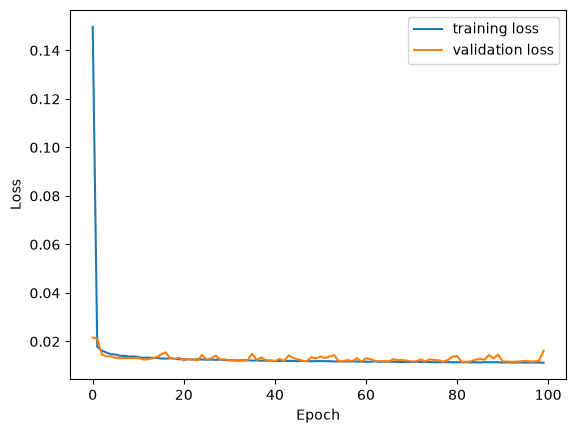

In [ ]:
metrics = pd.read_csv("logs/training_logs/version_0metrics.csv")

losses = metrics.groupby("epoch")[["epoch","train_loss", "val_loss"]].mean()
losses["epoch"]=losses["epoch"].astype("int")

plt.plot(losses["epoch"], losses["train_loss"], label="training loss")
plt.plot(losses["epoch"], losses["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()